# SGD basket mean reversion: execution and cost audit

**Result: no robust net edge demonstrated.** Thirty-four individual configurations were tested on development/validation data. No adequately active new policy had positive net Sharpe in both periods. A frozen shortlist also failed the 2024–2025 evaluation.

[Detailed report](sgd_neer_research_report.md) · [Reproduction instructions](sgd_neer_results/README.md)

The original `sgd_neer.ipynb` is preserved. This companion reads saved research results; running all cells does not download quotes or submit orders. The final period was excluded from this run's selection but was already present in the earlier exploratory notebook, so it is not independently pristine evidence.

**Execution update:** The original sections below use a one-bar delay. The appended **same-bar execution** section reruns all 34 configurations with zero-delay fills and matching forecast targets. [Follow-up report](sgd_neer_same_bar_report.md).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

search = [Path.cwd(), *Path.cwd().parents]
roots = [p / suffix for p in search for suffix in
         ("sgd_neer_results", "src/systematic_trading/research/sgd_neer_codex/sgd_neer_results")]
results = next(p for p in roots if (p / "comparison_evaluation.csv").exists())
comparison = pd.read_csv(results / "comparison_evaluation.csv")
development = pd.read_csv(results / "comparison_development.csv")
stress = pd.read_csv(results / "stress_evaluation.csv")
daily = pd.read_csv(results / "daily_evaluation.csv.gz", index_col=0, parse_dates=True)
variance_ratio = pd.read_csv(results / "variance_ratio.csv")
regressions = pd.read_csv(results / "return_regression.csv")
freeze = json.loads((results / "frozen_selection.json").read_text())
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "font.size": 10})
print(freeze["decision_before_evaluation"])


REJECT: no eligible new policy has positive Sharpe in both development and validation. Evaluate the fixed shortlist for diagnosis only.


## Correct basket replication

For one unit of the five-currency index, USDSGD exposure must be **−1**, because every SGD cross contains that leg. The old loop overwrote it with the final currency's raw weight (−0.0182). Other legs also used unnormalised weights. The signal and executed portfolio therefore differed.

The corrected strategy uses a common normalisation for returns, signals and costs, and purges regression labels by their actual completion timestamps.

In [2]:
manifest = json.loads((results / "data_manifest_evaluation.json").read_text())
display(pd.Series(manifest["audit"]["loadings"], name="Pair loading per index unit").to_frame())
display(pd.read_csv(results / "data_quality_evaluation.csv"))
print("Full-sample median round-trip spread:", round(manifest["audit"]["median_round_trip_bps"], 2), "bp")
print("Share of assumed full-basket weights represented:", round(100*manifest["audit"]["raw_weight_coverage"], 1), "%")

Full-sample median round-trip spread: 1.57 bp
Share of assumed full-basket weights represented: 49.2 %


,Pair loading per index unit
USDSGD,-1.000000
EURUSD,-0.285741
AUDUSD,-0.123574
GBPUSD,-0.034601
USDJPY,0.178327


,year,rows,complete_rows,USDSGD_missing,EURUSD_missing,AUDUSD_missing,GBPUSD_missing,USDJPY_missing
0,2020,24847,24680,161,136,136,139,135
1,2021,24752,24641,109,85,85,84,84
2,2022,24752,24683,41,4,17,12,12
3,2023,24752,18408,3320,3276,3282,3318,3299
4,2024,24847,24524,112,83,136,88,149
5,2025,24751,24679,63,64,61,64,61


## Reversal survives statistically, but much of it precedes a delayed fill

Diagnostics below use **2020–2023 only**. Variance ratios use contiguous observations and are descriptive, not a formal stationarity or profitability test. The regression example uses a two-hour past return and a thirty-minute future return. HAC standard errors account for overlapping windows.

After a 15-minute delay, a 10 bp move predicts only about 0.24 bp of reversal in this linear regression; the development basket spread is around 1.71 bp round trip.

,delay_bars,beta,hac_t,r_squared,n
9,0,-0.04802,-10.93040,0.00753,88688
10,1,-0.02430,-5.94053,0.00193,88342
11,2,-0.01646,-4.22562,0.00089,87996


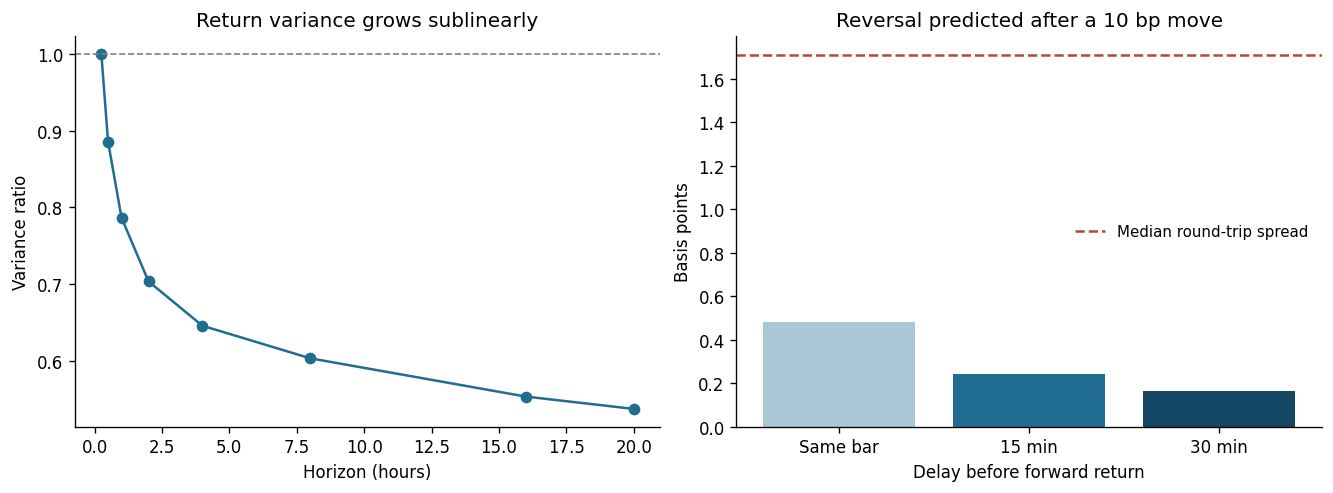

In [3]:
example = regressions.query("past_bars == 8 and future_bars == 2")
display(example[["delay_bars", "beta", "hac_t", "r_squared", "n"]].round(5))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(variance_ratio.minutes/60, variance_ratio.variance_ratio, "o-", color="#216c91")
axes[0].axhline(1, ls="--", color="0.5", lw=1)
axes[0].set(xlabel="Horizon (hours)", ylabel="Variance ratio", title="Return variance grows sublinearly")
axes[1].bar(["Same bar", "15 min", "30 min"], -10*example.beta, color=["#a8c8d6", "#216c91", "#134763"])
axes[1].axhline(1.7105, ls="--", color="#b24a3a", label="Median round-trip spread")
axes[1].set(xlabel="Delay before forward return", ylabel="Basis points", title="Reversal predicted after a 10 bp move")
axes[1].legend(frameon=False, fontsize=9)
fig.savefig(results / "signal_and_cost.png", dpi=160)
plt.show()

## Development search, including unsuccessful trials

2020 is warm-up; 2021–2022 is the common development period; 2023 is validation. The initial 18 configurations were extended with 12 no-trade-region and four component-execution configurations, all before final evaluation. Ranking uses the lower development/validation net Sharpe and requires at least **40 validation days with trades**. The circle with positive Sharpes in both periods traded on just one validation day and is excluded.

The final shortlist was frozen before scoring 2024–2025. An equal-weight ensemble of its three signals was also fixed; shared trades are netted before costs.

period,development,validation,validation_trade_days,eligible,selection_score
policy,,,,,
band_48_52_2,-0.058,-0.416,51,True,-0.416
equilibrium_16_2,-0.688,0.331,44,True,-0.688
band_16_52_1,-0.625,-0.946,80,True,-0.946
band_48_52_1,-1.135,-0.912,81,True,-1.135
band_4_12_1,-1.068,-1.187,42,True,-1.187
equilibrium_16_1.5,-1.633,0.094,102,True,-1.633
band_16_12_1,-2.119,-2.041,48,True,-2.119
reversal_32_1.5,-2.238,-0.221,90,True,-2.238
components_16_all,0.076,-2.606,81,True,-2.606


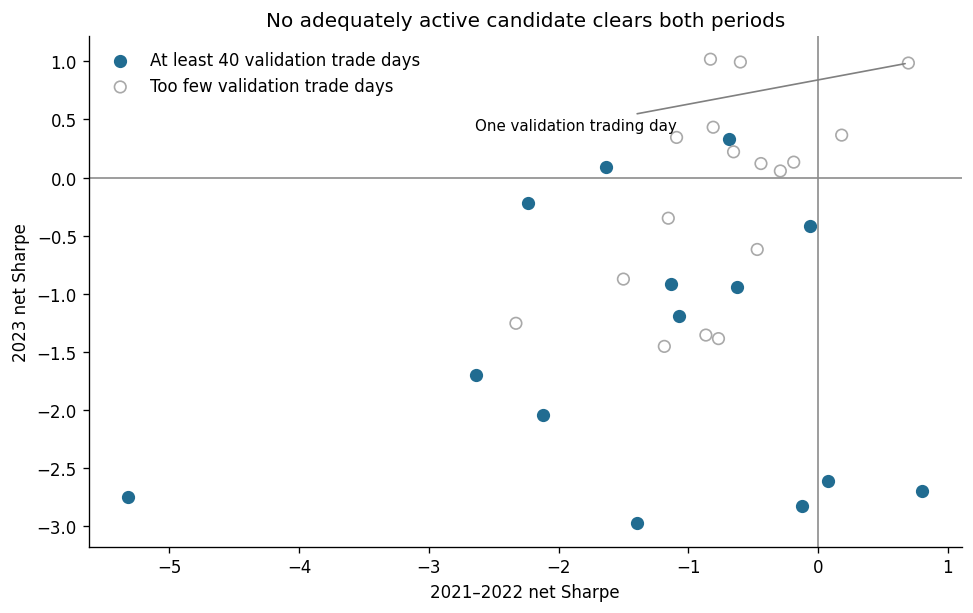

In [4]:
new = development[~development.policy.str.startswith("legacy")]
board = new.pivot(index="policy", columns="period", values="sharpe")
board["validation_trade_days"] = new.query("period == 'validation'").set_index("policy").trade_days
board["eligible"] = board.validation_trade_days >= 40
board["selection_score"] = board[["development", "validation"]].min(axis=1).where(board.eligible)
board = board.sort_values("selection_score", ascending=False)
display(board.round(3))
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for eligible, color, label in [(True, "#216c91", "At least 40 validation trade days"),
                               (False, "#a9a9a9", "Too few validation trade days")]:
    part = board[board.eligible == eligible]
    ax.scatter(part.development, part.validation, s=48, label=label,
               facecolors=color if eligible else "none", edgecolors=color)
ax.axhline(0, color="0.55", lw=1)
ax.axvline(0, color="0.55", lw=1)
point = board.loc["band_4_52_2"]
ax.annotate("One validation trading day", (point.development, point.validation),
            xytext=(-260, -40), textcoords="offset points", fontsize=9,
            arrowprops={"arrowstyle":"-", "color":"0.5"})
ax.set(xlabel="2021–2022 net Sharpe", ylabel="2023 net Sharpe", title="No adequately active candidate clears both periods")
ax.legend(frameon=False, loc="upper left")
fig.savefig(results / "development_search.png", dpi=160)
plt.show()

## Frozen evaluation

Signals observe a completed bar, fill at the following available quote, and earn the subsequent return. Costs include all five legs, all adjustments and final liquidation. Held-position returns across gaps are retained. Sharpe uses daily New York trading-date PnL.

The original control uses the archived original signals and original incorrect mapping, re-evaluated under this common execution engine. The corrected controls use the actual basket. Base PnL excludes financing; legacy controls have rollover exposure. The new shortlisted policies were flat at every evaluation-period rollover.

period,development,validation,2024,2025,evaluation
policy,,,,,
band_16_52_1,-0.625,-0.946,-2.009,-0.553,-1.113
band_48_52_2,-0.058,-0.416,-1.399,0.263,-0.647
equilibrium_16_2,-0.688,0.331,-1.228,-1.945,-1.624
frozen_ensemble,-0.639,-0.255,-1.684,-1.816,-1.752
legacy_corrected,-2.022,-3.222,-2.718,-1.926,-2.294
legacy_mapping_only,-2.069,-3.131,-4.181,-1.926,-2.834
legacy_original,0.123,-0.037,-0.628,-0.138,-0.321


,gross_sharpe,sharpe,trade_days,annual_vol,max_drawdown,bootstrap_low,bootstrap_high,break_even_cost_multiple,rollover_events_with_exposure
policy,,,,,,,,,
legacy_original,0.3919,-0.3209,307,0.0000,-0.0000,-1.3272,0.8509,0.5486,123
legacy_mapping_only,2.1637,-2.8345,307,0.0000,-0.0000,-3.7976,-1.9223,0.4074,123
legacy_corrected,2.0838,-2.2941,267,0.0000,-0.0000,-3.0979,-1.4200,0.4525,137
band_48_52_2,0.8022,-0.6470,88,0.0041,-0.0137,-2.4949,1.0089,0.5577,0
equilibrium_16_2,-0.0734,-1.6241,105,0.0124,-0.0467,-2.4655,-0.6322,-0.0452,0
band_16_52_1,0.3809,-1.1134,127,0.0053,-0.0123,-2.6426,0.2769,0.2535,0
frozen_ensemble,0.2873,-1.7524,201,0.0054,-0.0211,-2.6873,-0.6116,0.1357,0


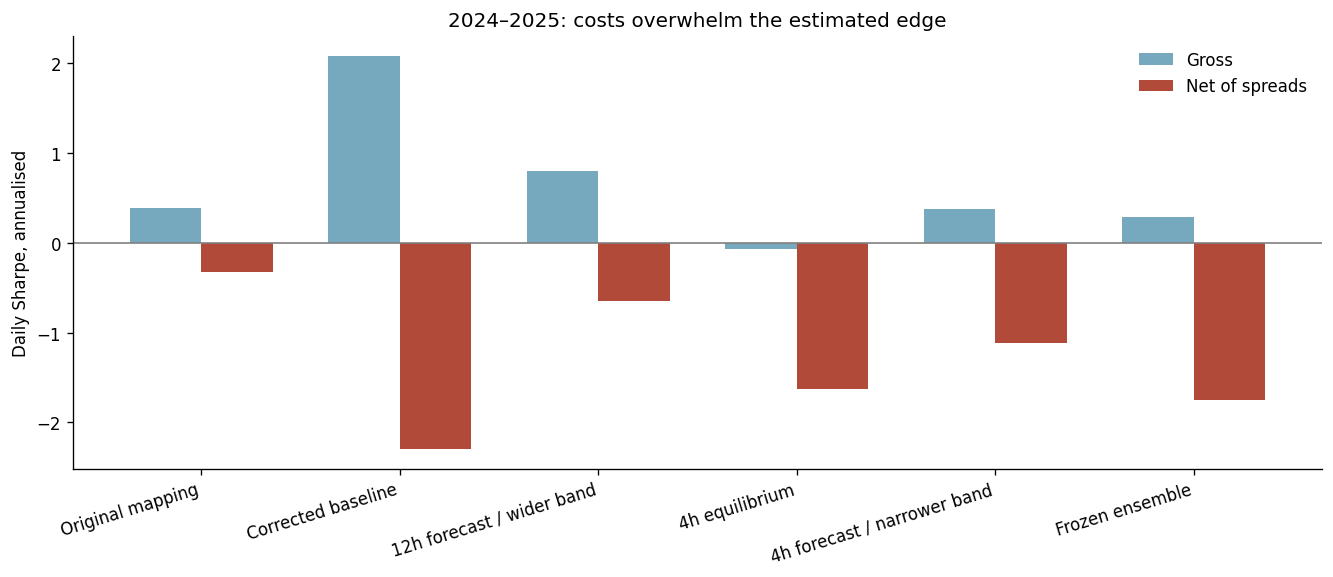

In [5]:
table = comparison.pivot(index="policy", columns="period", values="sharpe")
display(table[["development", "validation", "2024", "2025", "evaluation"]].round(3))
evaluation = comparison.query("period == 'evaluation'").set_index("policy")
display(evaluation[["gross_sharpe", "sharpe", "trade_days", "annual_vol", "max_drawdown",
                    "bootstrap_low", "bootstrap_high", "break_even_cost_multiple",
                    "rollover_events_with_exposure"]].round(4))
labels = {"legacy_original":"Original mapping", "legacy_corrected":"Corrected baseline",
          "band_48_52_2":"12h forecast / wider band", "equilibrium_16_2":"4h equilibrium",
          "band_16_52_1":"4h forecast / narrower band", "frozen_ensemble":"Frozen ensemble"}
order = list(labels)
fig, ax = plt.subplots(figsize=(11, 4.7), layout="constrained")
x = np.arange(len(order))
ax.bar(x-.18, evaluation.loc[order, "gross_sharpe"], width=.36, label="Gross", color="#76a9bd")
ax.bar(x+.18, evaluation.loc[order, "sharpe"], width=.36, label="Net of spreads", color="#b24a3a")
ax.axhline(0, color="0.5", lw=1)
ax.set_xticks(x, [labels[n] for n in order], rotation=17, ha="right")
ax.set(ylabel="Daily Sharpe, annualised", title="2024–2025: costs overwhelm the estimated edge")
ax.legend(frameon=False)
fig.savefig(results / "evaluation_sharpes.png", dpi=160)
plt.show()

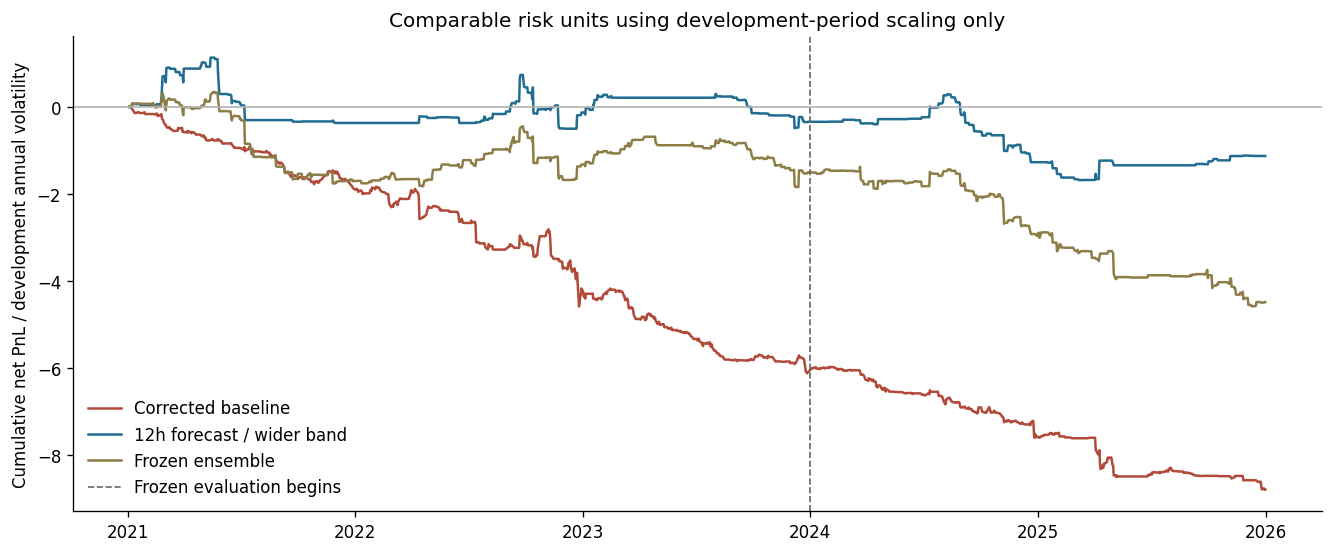

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
for name, color in [("legacy_corrected", "#b24a3a"), ("band_48_52_2", "#216c91"),
                     ("frozen_ensemble", "#8d7e47")]:
    net = daily[f"{name}__net"]
    scale = net.loc["2021":"2022"].std()*np.sqrt(252)
    ax.plot(net.loc["2021":].cumsum()/scale, label=labels[name], color=color, lw=1.5)
ax.axvline(pd.Timestamp("2024-01-01"), color="0.4", ls="--", lw=1, label="Frozen evaluation begins")
ax.axhline(0, color="0.7", lw=1)
ax.set(ylabel="Cumulative net PnL / development annual volatility",
       title="Comparable risk units using development-period scaling only")
ax.legend(frameon=False)
fig.savefig(results / "cumulative_pnl.png", dpi=160)
plt.show()

## Execution and cost stress

The strongest eligible new rule is still negative: net Sharpe −0.65, versus +0.80 before spreads. Cutting the spread cost in half reaches only +0.09. Same-bar fills are an optimistic diagnostic, not a verified execution assumption. Bootstrap intervals are descriptive and do not adjust for model selection.

In [7]:
sensitivity = stress.pivot(index="scenario", columns="policy", values="sharpe")
display(sensitivity[["legacy_corrected", "band_48_52_2", "frozen_ensemble"]].round(3))

policy,legacy_corrected,band_48_52_2,frozen_ensemble
scenario,,,
1bp_per_roll_exposure,-2.806,-0.647,-1.752
base,-2.294,-0.647,-1.752
extra_0.25bp_per_leg,-4.077,-1.214,-2.571
half_spread_cost,-0.219,0.085,-0.761
same_bar_optimistic,-0.519,0.198,-0.824
spread_x1.5,-3.775,-1.338,-2.645
spread_x2,-4.729,-1.946,-3.418
two_bar_delay,-2.653,-1.843,-2.959


## Reuse and next experiments

The new reusable code is in `research.sgd_neer_codex.sgd_neer_backtest`: `prepare_basket`, `Policy`, `rolling_forecast`, `policy_signal`, `backtest`, and `component_forecast_signals`. For example, the frozen diagnostic policy is:

```python
policy = Policy("band_48_52_2", kind="forecast_band",
                forecast_horizon=48, training_weeks=52, cost_hurdle=2)
data = prepare_basket(prices)
signal = policy_signal(data, policy)
pnl = backtest(data, signal)  # no orders; next-quote execution
```

This is a **rejected research candidate**, not a deployment recommendation. Reproduce all trials and the fixed evaluation from the repository root:

```sh
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_research.py --phase development
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_research.py --phase evaluation
```

The next useful work is to verify sub-bar executable quotes and quote age; obtain the missing Asian basket constituents; and test a crawling-equilibrium model with policy regimes and financing on new data. More threshold optimisation on the same proxy is unlikely to resolve the demonstrated gap between expected reversal and costs.

MAS describes a basket that can float within a crawling policy band, which is not a guarantee of short-horizon reversal: [official framework](https://www.mas.gov.sg/monetary-policy/singapores-monetary-policy-framework/faqs/section-2). For the relationship between predictable returns and gradual trading, see [Gârleanu–Pedersen](https://www.nber.org/papers/w15205).

## Same-bar execution: full follow-up

A 15-minute wait is too coarse to be the only primary execution assumption for tick-derived quotes. This follow-up observes the quote at t, trades at that quote's bid/ask, and earns only returns after t. **It never earns the return used to calculate the signal.**

All 34 policies were rerun. Forecast labels now use `level[t+h] - level[t]`; earlier forecast models used `level[t+1+h] - level[t+1]`. The previous same-bar stress changed fills but retained those earlier forecast models. The baseline already used immediate-return labels.

[Follow-up report and reproduction commands](sgd_neer_same_bar_report.md). These are previously seen evaluation dates, not a fresh untouched test.

,Earlier one-bar study,"Earlier model, immediate fill",Same-bar rerun
policy,,,
legacy_corrected,-2.294,-0.519,-0.519
equilibrium_16_2,-1.624,-0.929,-0.929
band_48_52_2,-0.647,0.198,-0.452
band_16_52_2,NaN,NaN,-0.447


period,development,validation,2024,2025,evaluation
policy,,,,,
band_16_52_2,-0.270,0.111,-0.721,-0.195,-0.447
band_48_52_2,-0.269,0.228,-1.669,0.595,-0.452
equilibrium_16_2,0.095,1.358,-0.393,-1.302,-0.929
frozen_ensemble,-0.078,0.947,-0.959,-0.879,-0.920
legacy_corrected,-0.850,-2.473,-0.908,-0.246,-0.519
legacy_mapping_only,-0.780,-1.224,-1.104,-0.681,-0.840
legacy_original,0.244,0.856,-0.959,-0.254,-0.505


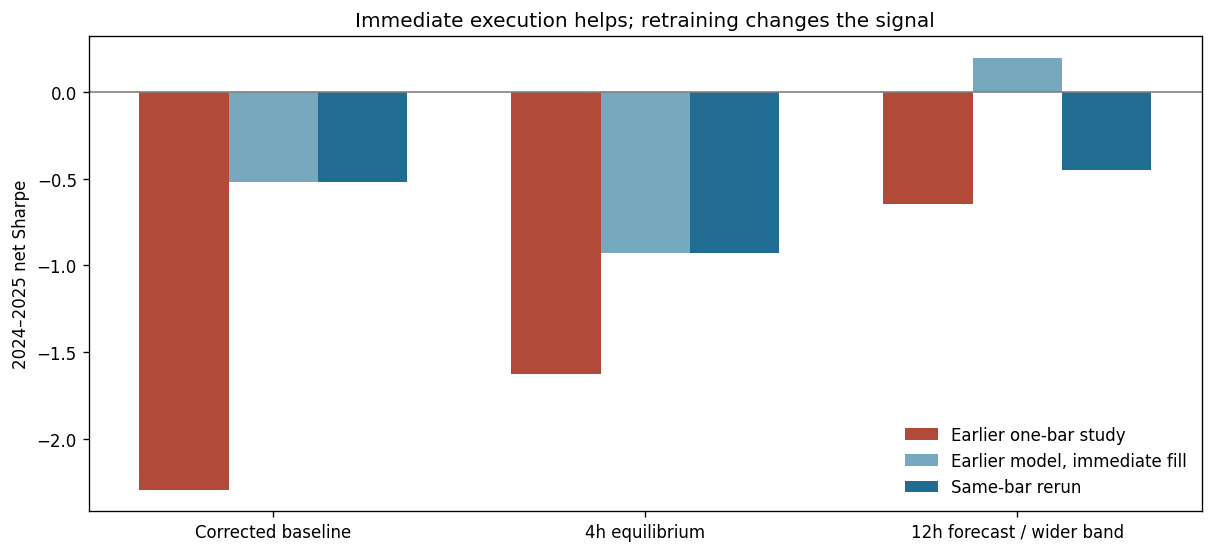

In [8]:
same_bar = pd.read_csv(results / "delay_0/comparison_evaluation.csv")
same_eval = same_bar.query("period == 'evaluation'").set_index("policy")
previous_eval = comparison.query("period == 'evaluation'").set_index("policy")
previous_same = stress.query("scenario == 'same_bar_optimistic'").set_index("policy")
comparison_zero = pd.DataFrame({
    "Earlier one-bar study": previous_eval.sharpe,
    "Earlier model, immediate fill": previous_same.sharpe,
    "Same-bar rerun": same_eval.sharpe,
}).reindex(["legacy_corrected", "equilibrium_16_2", "band_48_52_2", "band_16_52_2"])
display(comparison_zero.round(3))
display(same_bar.pivot(index="policy",columns="period",values="sharpe")
        [["development","validation","2024","2025","evaluation"]].round(3))

labels_zero = ["Corrected baseline", "4h equilibrium", "12h forecast / wider band"]
figure, axis = plt.subplots(figsize=(10,4.5), layout="constrained")
positions = np.arange(3)
for offset, (column,color) in enumerate(zip(comparison_zero.columns, ["#b24a3a","#76a9bd","#216c91"])):
    axis.bar(positions+(offset-1)*.24, comparison_zero.iloc[:3][column], width=.24,
             label=column,color=color)
axis.axhline(0,color="0.5",lw=1)
axis.set_xticks(positions,labels_zero)
axis.set(ylabel="2024–2025 net Sharpe",title="Immediate execution helps; retraining changes the signal")
axis.legend(frameon=False,loc="lower right")
figure.savefig(results / "delay_0/execution_comparison.png",dpi=160)
plt.show()

The earlier frozen 12-hour forecast candidate returns **+0.20** with same-bar fills and its original forecasts. The newly retrained version returns **−0.45**. These are different signals, so the figures are not contradictory.

The corrected baseline improves from **−2.29 to −0.52** net Sharpe. The 4-hour equilibrium rule is the only new adequately active rule that clears development and validation, but then returns **−0.93** in 2024–2025. Costs and instability remain material after removing the delay.

This run uses cached 15-minute bid/ask quotes, not a tick fill replay. The configured local raw-tick directory currently has no tick CSVs. All 11 timing, cost and causality tests pass.

```python
policy = Policy("same_bar", kind="forecast_band", forecast_horizon=48,
                training_weeks=52, cost_hurdle=2, execution_delay=0)
signal = policy_signal(data, policy)  # zero-delay training labels
pnl = backtest(data, signal, delay=0)  # current-quote bid/ask fills
```

```sh
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_research.py --phase development --execution-delay 0
poetry run python src/systematic_trading/research/sgd_neer_codex/run_sgd_neer_research.py --phase evaluation --execution-delay 0
```